# Measuring strategy risk from a return path

A delayed position turns public index returns into a strategy wealth path:

$$
r_t^{S}=q_{t-1}r_t,
\qquad
W_t=\prod_{j=1}^{t}(1+r_j^{S}),
\qquad
D_t=1-\frac{W_t}{\max_{1\leq j\leq t}W_j}.
$$

Here, $r_t$ is the simple index return on day $t$, $q_{t-1}\in\{-1,1\}$ is the position chosen using earlier prices, $r_t^{S}$ is the strategy return, $W_t$ is wealth from one initial unit, and $D_t$ is the proportional decline from the running wealth peak.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import hashlib
import math
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

DATA_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
DATA_DIR = ROOT / "data" / "public" / "fred"
DATA_PATH = ensure_dataset(ROOT, "fred_sp500")
EXPECTED_DATA_HASH = "2098B209EE3AFDB3B2C1E783AC90A2BB7DD3865FEB416D0FABEDBB4A7A542754"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
raw = pd.read_csv(DATA_PATH)
raw["observation_date"] = pd.to_datetime(raw["observation_date"])
prices = raw.set_index("observation_date")["SP500"].dropna().astype(float).sort_index()
simple_returns = prices.pct_change()
log_returns = np.log(prices).diff()

FIGURES = ROOT / "outputs" / "figures" / "22_position_sizing"
TABLES = ROOT / "outputs" / "tables" / "22_position_sizing"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

data_provenance = pd.DataFrame({
    "Field": ["Series", "Provider", "Source", "Retrieved", "First price", "Last price", "Price observations", "File SHA256"],
    "Value": ["S&P 500", "Federal Reserve Bank of St. Louis", DATA_URL, "2026-09-28", str(prices.index.min().date()), str(prices.index.max().date()), len(prices), data_hash],
})

from RiskLabAI.backtest.backtest_statistics import bet_timing, calculate_hhi, calculate_hhi_concentration, calculate_holding_period, compute_drawdowns_time_under_water, sharpe_ratio
from RiskLabAI.backtest.robust_statistics import conditional_expected_drawdown
from RiskLabAI.backtest.strategy_risk import bin_frequency, binomial_sharpe_ratio, implied_precision, mix_gaussians, target_sharpe_ratio_symbolic

fast_average = prices.ewm(span=5, adjust=False, min_periods=5).mean()
slow_average = prices.ewm(span=30, adjust=False, min_periods=30).mean()
target_positions = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1).dropna()
aligned_returns = simple_returns.reindex(target_positions.index).fillna(0.0)
strategy_returns = (target_positions * aligned_returns).rename("Strategy return")
strategy_wealth = (1.0 + strategy_returns).cumprod().rename("Strategy wealth")
index_wealth = (1.0 + aligned_returns).cumprod().rename("Index wealth")
running_peak = strategy_wealth.cummax()
drawdown_path = (1.0 - strategy_wealth / running_peak).rename("Drawdown")
elapsed_years = (strategy_returns.index[-1] - strategy_returns.index[0]).days / 365.25

def compound_bet_returns(positions, returns):
    groups = positions.ne(positions.shift()).cumsum()
    values = returns.groupby(groups).apply(lambda sample: (1.0 + sample).prod() - 1.0)
    dates = positions.groupby(groups).apply(lambda sample: sample.index[-1])
    sides = positions.groupby(groups).first()
    frame = pd.DataFrame({"End date": dates.to_numpy(), "Side": sides.to_numpy(), "Bet return": values.to_numpy()})
    frame["End date"] = pd.to_datetime(frame["End date"])
    return frame

public_bets = compound_bet_returns(target_positions, strategy_returns)

def circular_block_sample(values, sample_length, block_length, rng):
    values = np.asarray(values, dtype=float)
    block_count = int(np.ceil(sample_length / block_length))
    starts = rng.integers(0, len(values), size=block_count)
    offsets = np.arange(block_length)
    locations = ((starts[:, None] + offsets[None, :]) % len(values)).reshape(-1)[:sample_length]
    return values[locations]

def maximum_drawdown(returns):
    wealth = np.cumprod(1.0 + np.asarray(returns, dtype=float))
    peak = np.maximum.accumulate(wealth)
    return float(np.max(1.0 - wealth / peak))
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Strategy Track

,Field,Value
0,Series,S&P 500
1,Provider,Federal Reserve Bank of St. Louis
2,Source,https://fred.stlouisfed.org/graph/fredgraph.cs...
3,Rule,Sign of the five-day minus thirty-day exponent...
4,Position delay,One observed day
5,File SHA256,2098B209EE3AFDB3B2C1E783AC90A2BB7DD3865FEB416D...


,Quantity,Value
0,Price observations,2330
1,Strategy-return observations,2300
2,First strategy date,2016-11-07
3,Last strategy date,2025-12-31
4,Elapsed years,9.147159
5,Ending strategy wealth,1.657947
6,Ending index wealth,3.28293
7,Annualized strategy return,0.056828
8,Annualized index return,0.138779
9,Annualized strategy Sharpe,0.391955


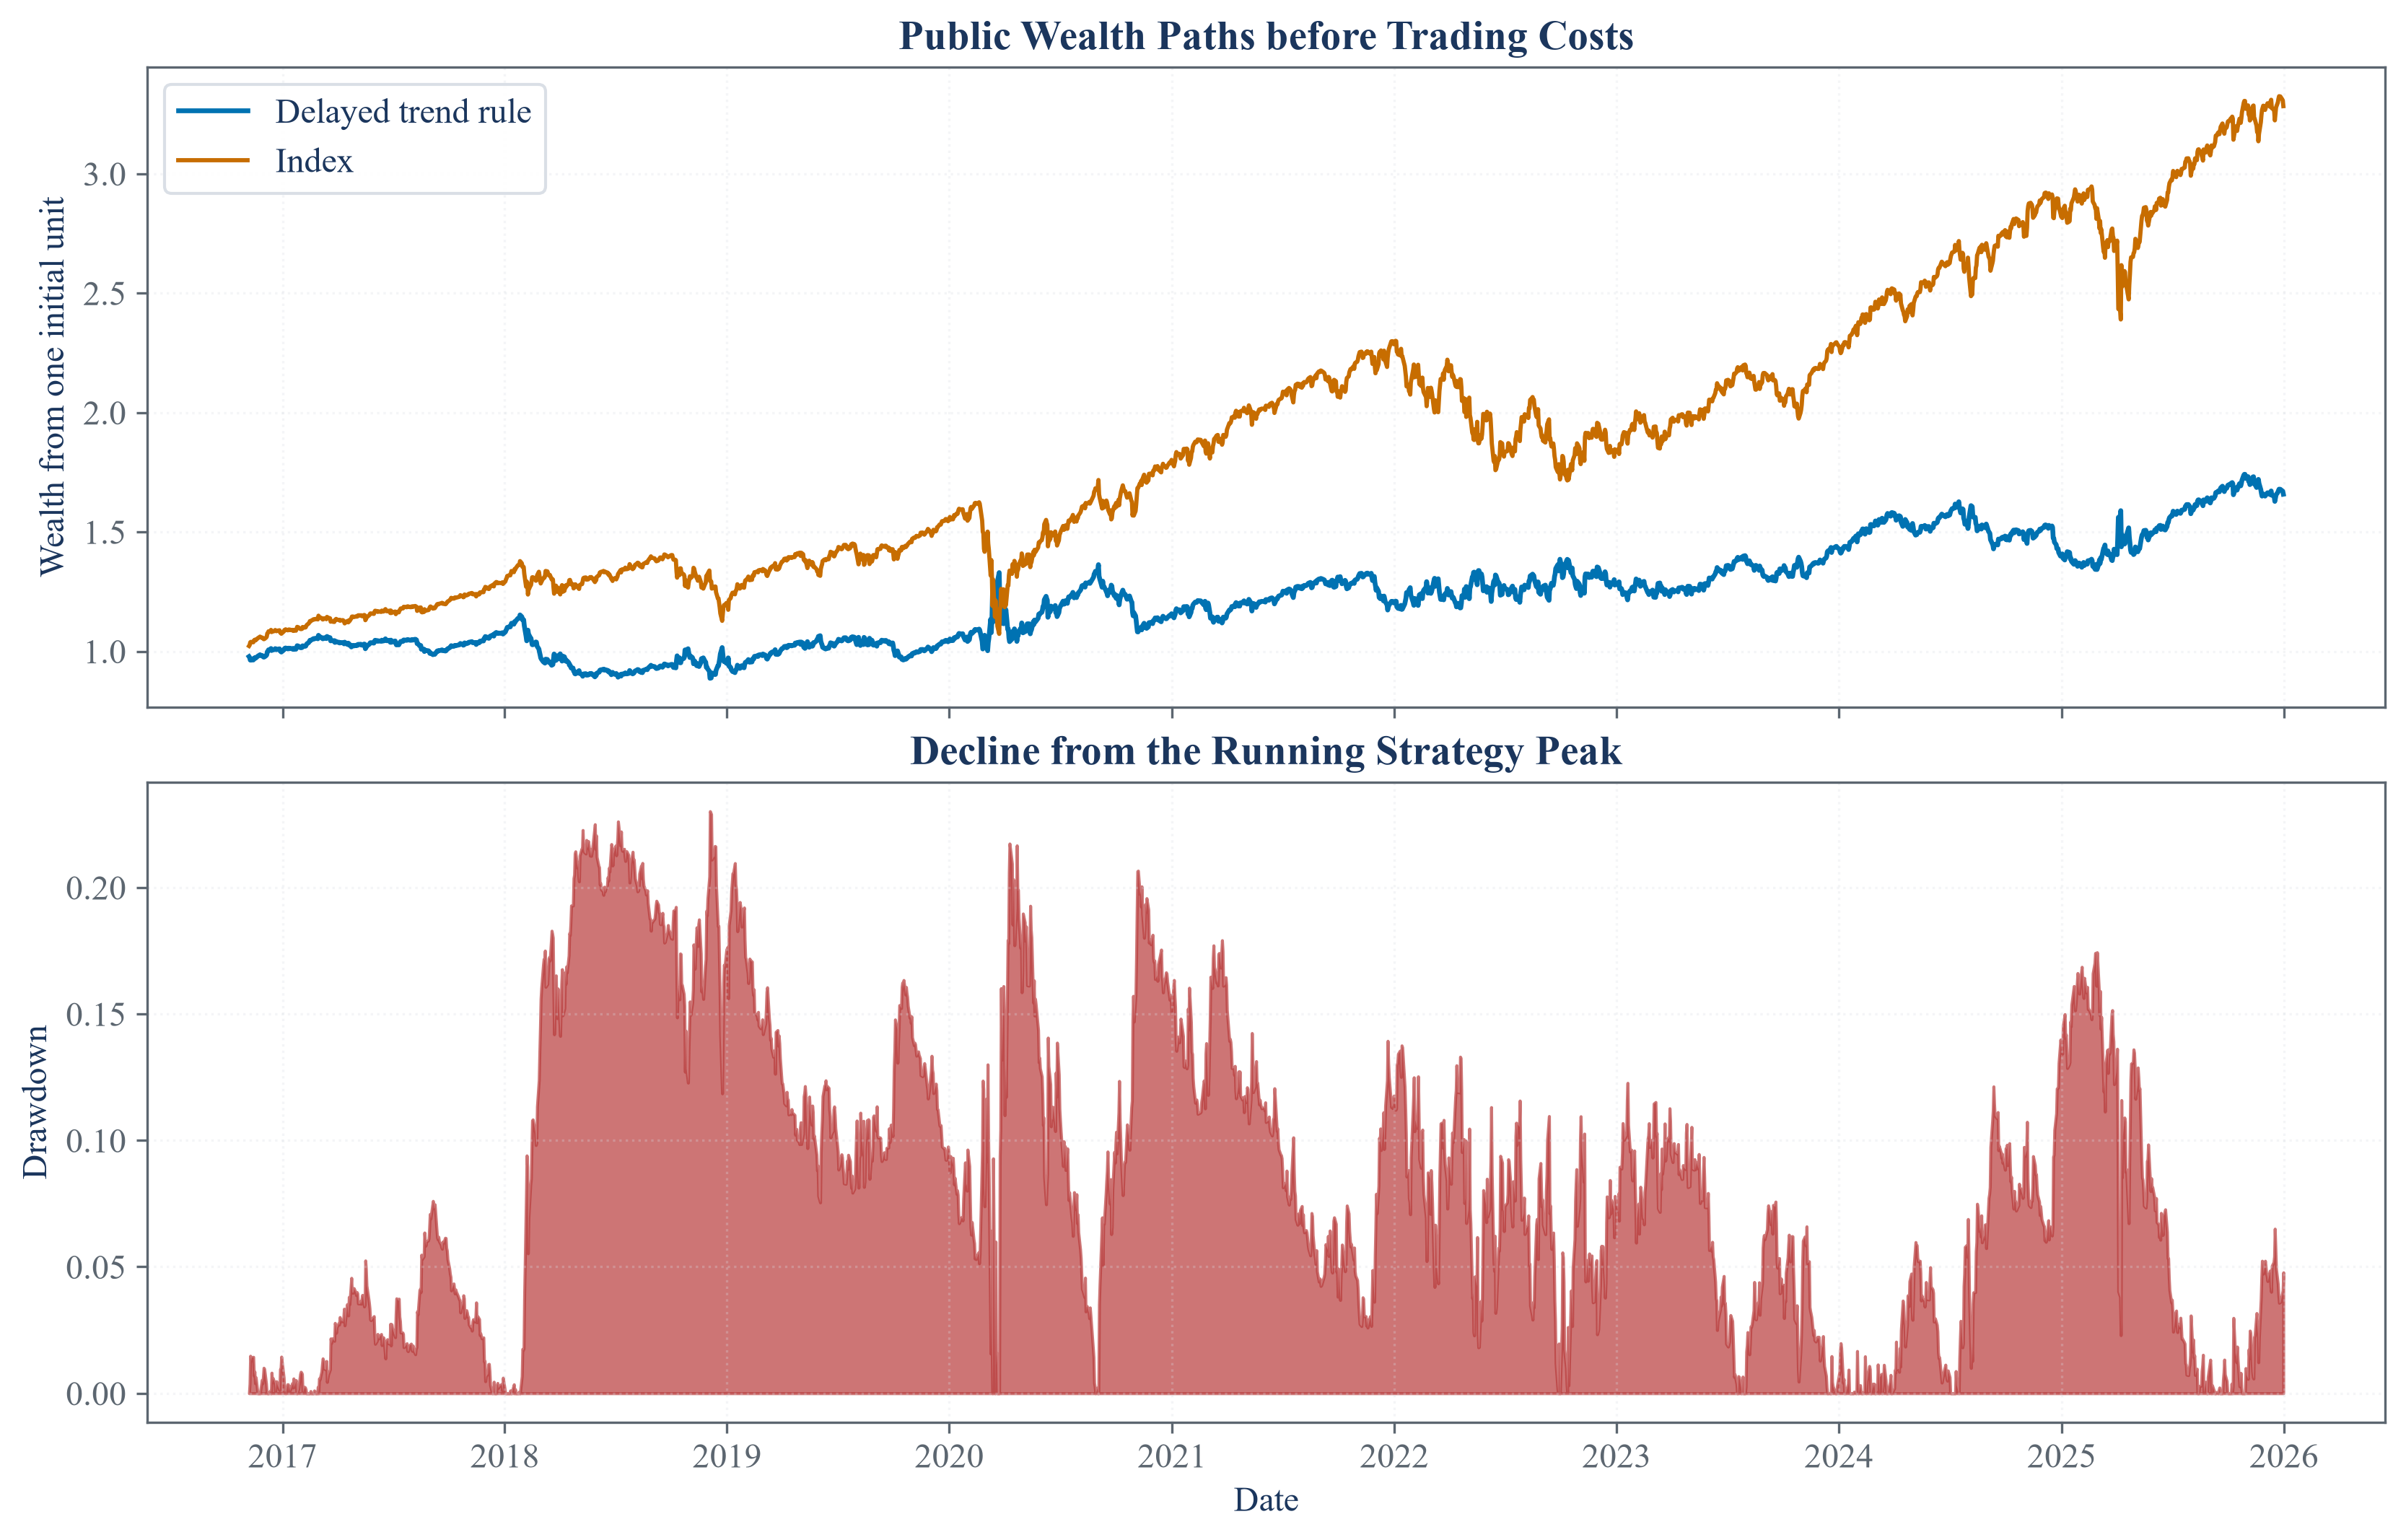

In [2]:
public_performance_summary = pd.DataFrame({
    "Quantity": ["Price observations", "Strategy-return observations", "First strategy date", "Last strategy date", "Elapsed years", "Ending strategy wealth", "Ending index wealth", "Annualized strategy return", "Annualized index return", "Annualized strategy Sharpe", "Largest path drawdown"],
    "Value": [len(prices), len(strategy_returns), str(strategy_returns.index.min().date()), str(strategy_returns.index.max().date()), elapsed_years, strategy_wealth.iloc[-1], index_wealth.iloc[-1], strategy_wealth.iloc[-1] ** (1.0 / elapsed_years) - 1.0, index_wealth.iloc[-1] ** (1.0 / elapsed_years) - 1.0, sharpe_ratio(strategy_returns.to_numpy()) * np.sqrt(252.0), drawdown_path.max()],
})
strategy_data_provenance = pd.DataFrame({
    "Field": ["Series", "Provider", "Source", "Rule", "Position delay", "File SHA256"],
    "Value": ["S&P 500", "Federal Reserve Bank of St. Louis", DATA_URL, "Sign of the five-day minus thirty-day exponential moving average", "One observed day", data_hash],
})
save_table(strategy_data_provenance, "strategy_data_provenance", "Public observations used for the performance-risk study.", "tab:chapter19-strategy-data")
save_table(public_performance_summary, "public_performance_summary", "Public strategy and index performance before trading costs.", "tab:chapter19-performance-summary", fit=False)
display(strategy_data_provenance)
display(public_performance_summary)

figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.0), sharex=True, constrained_layout=True)
axes[0].plot(strategy_wealth.index, strategy_wealth, color=palette["cyan"], linewidth=1.6, label="Delayed trend rule")
axes[0].plot(index_wealth.index, index_wealth, color=palette["amber"], linewidth=1.4, label="Index")
axes[0].set_title("Public Wealth Paths before Trading Costs")
axes[0].set_ylabel("Wealth from one initial unit")
axes[0].legend()
axes[0].grid(alpha=0.28)
axes[1].fill_between(drawdown_path.index, 0, drawdown_path, color=palette["rose"], alpha=0.70)
axes[1].set_title("Decline from the Running Strategy Peak")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Drawdown")
axes[1].grid(alpha=0.28)
save_figure(figure, "public_wealth_drawdown")

## Measuring concentration across bets

Weighted holding time and normalized concentration summarize the shape of a backtest:

$$
\overline H=\frac{\sum_{i=1}^{B}w_iH_i}{\sum_{i=1}^{B}w_i},
\qquad
HHI_N=\frac{\sum_{i=1}^{B}\omega_i^2-B^{-1}}{1-B^{-1}},
\qquad
\omega_i=\frac{x_i}{\sum_{j=1}^{B}x_j}.
$$

Here, $B$ is the number of completed position pieces, $H_i$ is the holding time of piece $i$, $w_i$ is the closed position amount, $\overline H$ is the weighted average holding time, $x_i$ is the return or count used in a concentration calculation, $\omega_i$ is its normalized share, and $HHI_N$ is normalized concentration.

,Quantity,Value
0,Bet-ending dates,84
1,Compounded sign runs,84
2,Bets per year,9.183179
3,Long bets,42
4,Short bets,42
5,Weighted holding period in days,39.855422
6,Positive-return concentration,0.001172
7,Negative-return concentration,0.001341
8,Monthly-count concentration,0.000032


,End date,Side,Bet return
35,2020-09-11,1,0.209782
81,2025-11-17,1,0.199895
67,2024-04-15,1,0.159378
43,2021-09-17,1,0.137011
27,2019-05-10,1,0.109827
61,2023-08-11,1,0.108307
1,2017-03-24,1,0.083541
41,2021-03-04,1,0.073501
11,2018-02-05,1,0.071729
40,2020-11-05,-1,-0.069714


,End date,Holding days,Closed position amount
0,2016-11-10,3,1
1,2017-03-27,137,1
2,2017-03-29,2,1
3,2017-04-13,15,1
4,2017-04-25,12,1
...,...,...,...
78,2025-01-22,22,1
79,2025-02-26,35,1
80,2025-04-30,63,1
81,2025-11-18,202,1


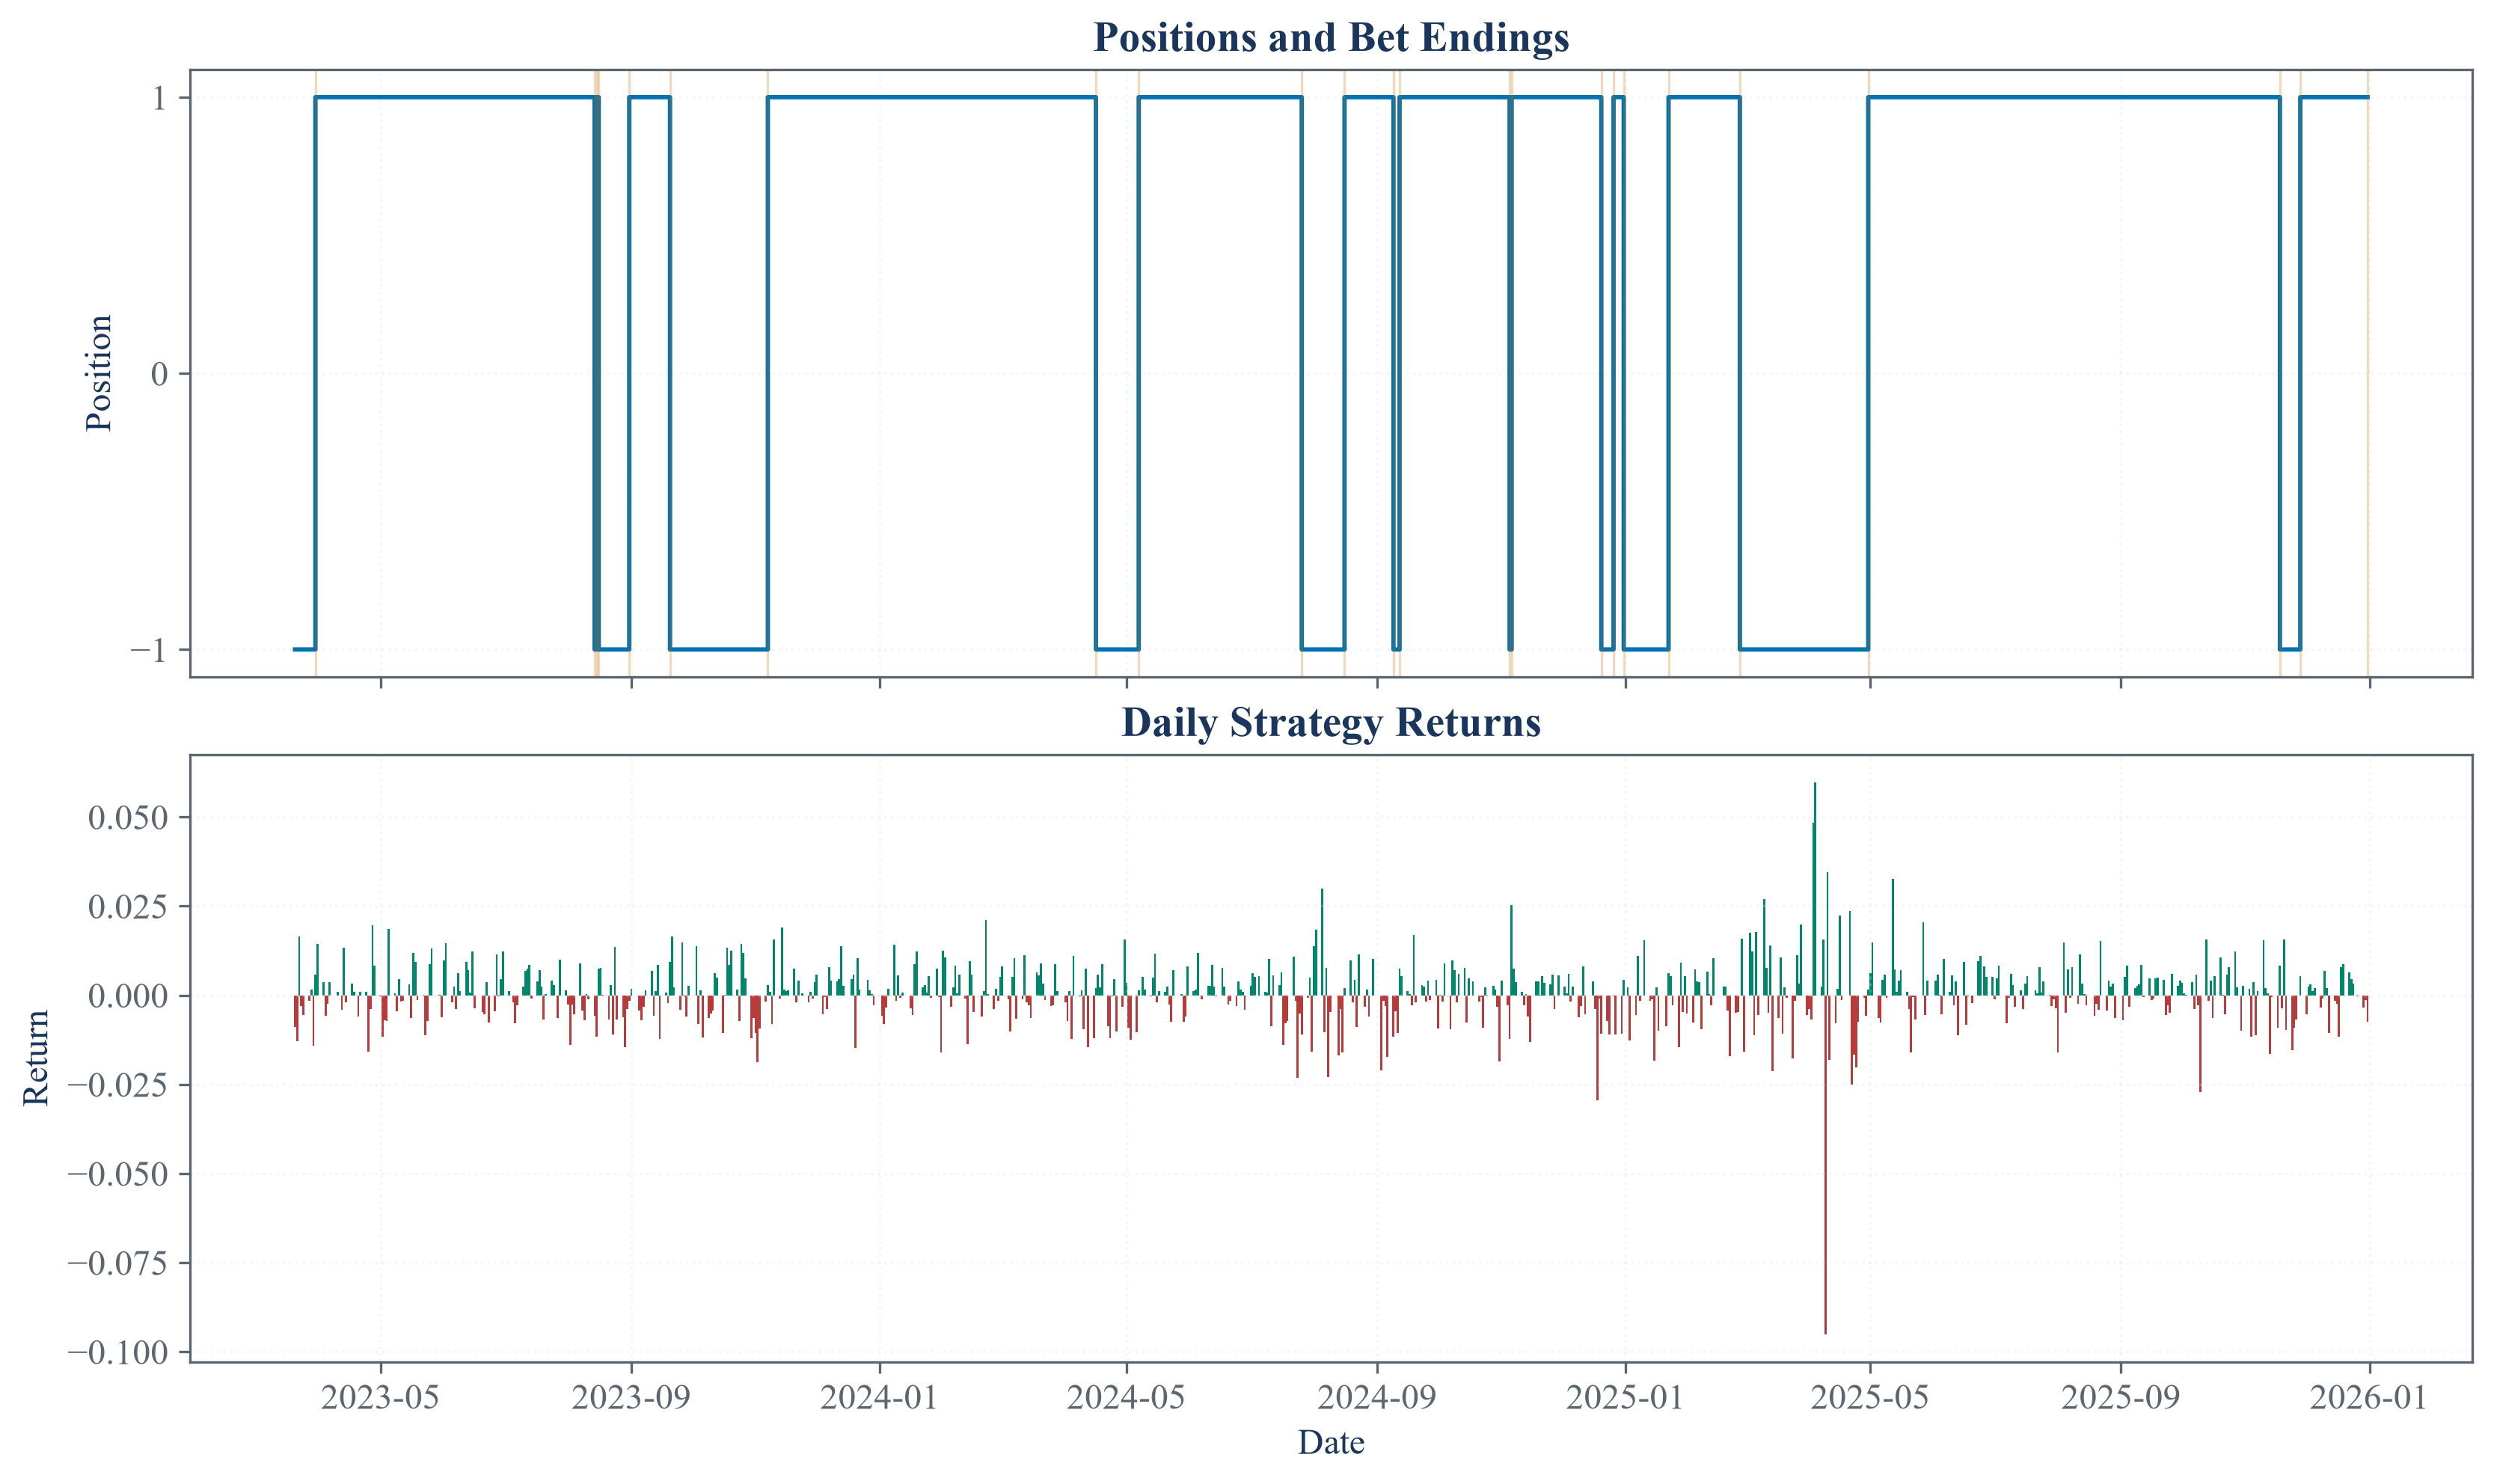

In [3]:
public_bet_dates = bet_timing(target_positions)
holding_detail, mean_holding_period = calculate_holding_period(target_positions)
_original_pandas_grouper = pd.Grouper
def _month_end_grouper(*args, **kwargs):
    if kwargs.get("freq") == "M":
        kwargs = dict(kwargs)
        kwargs["freq"] = "ME"
    return _original_pandas_grouper(*args, **kwargs)
pd.Grouper = _month_end_grouper
try:
    positive_hhi, negative_hhi, time_hhi = calculate_hhi_concentration(strategy_returns)
finally:
    pd.Grouper = _original_pandas_grouper
bet_summary = pd.DataFrame({
    "Quantity": ["Bet-ending dates", "Compounded sign runs", "Bets per year", "Long bets", "Short bets", "Weighted holding period in days", "Positive-return concentration", "Negative-return concentration", "Monthly-count concentration"],
    "Value": [len(public_bet_dates), len(public_bets), len(public_bets) / elapsed_years, int((public_bets["Side"] > 0).sum()), int((public_bets["Side"] < 0).sum()), mean_holding_period, positive_hhi, negative_hhi, time_hhi],
})
leading_bets = public_bets.assign(**{"Absolute return": public_bets["Bet return"].abs()}).sort_values("Absolute return", ascending=False).head(15).drop(columns="Absolute return")
leading_bets["End date"] = leading_bets["End date"].dt.strftime("%Y-%m-%d")
holding_table = holding_detail.reset_index().rename(columns={"index": "End date", "dT": "Holding days", "w": "Closed position amount"})
holding_table["End date"] = pd.to_datetime(holding_table["End date"]).dt.strftime("%Y-%m-%d")
save_table(bet_summary, "public_bet_summary", "Bet frequency, holding period, and concentration for the public rule.", "tab:chapter19-bet-summary", fit=False)
save_table(leading_bets, "largest_public_bets", "The fifteen public bets with the largest absolute compounded returns.", "tab:chapter19-largest-bets")
save_table(holding_table, "public_holding_detail", "Closed position pieces used in the weighted holding-period calculation.", "tab:chapter19-holding-detail")
display(bet_summary)
display(leading_bets)
display(holding_table)

recent_positions = target_positions.iloc[-700:]
recent_end_dates = public_bet_dates.intersection(recent_positions.index)
figure, axes = plt.subplots(2, 1, figsize=(11.0, 6.5), sharex=True, constrained_layout=True)
axes[0].step(recent_positions.index, recent_positions, where="post", color=palette["cyan"], linewidth=1.4)
for date in recent_end_dates:
    axes[0].axvline(date, color=palette["amber"], alpha=0.25, linewidth=0.8)
axes[0].set_title("Positions and Bet Endings")
axes[0].set_ylabel("Position")
axes[0].set_yticks([-1, 0, 1])
axes[0].grid(alpha=0.28)
recent_returns = strategy_returns.reindex(recent_positions.index)
axes[1].bar(recent_returns.index, recent_returns, color=np.where(recent_returns >= 0, palette["green"], palette["rose"]), width=1.0)
axes[1].set_title("Daily Strategy Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Return")
axes[1].grid(alpha=0.28)
save_figure(figure, "public_positions_bet_timing")

## Measuring drawdown depth and duration

Maximum drawdown and an empirical conditional expected drawdown are defined by:

$$
MDD_T=\max_{1\leq t\leq T}D_t,
\qquad
CED_{\alpha,h}=\frac{1}{1-\alpha}\int_{\alpha}^{1}Q_u\!\left(MDD_h\right)du.
$$

Here, $D_t$ is the drawdown at time $t$, $MDD_T$ is the largest drawdown over the complete horizon of $T$ observations, $h$ is a rolling measurement horizon, $MDD_h$ is the distribution of maximum drawdowns across those windows, $Q_u$ is its quantile at probability $u$, $\alpha$ is the tail threshold, and $CED_{\alpha,h}$ is the average of the worst $1-\alpha$ share of rolling maximum drawdowns.

,Peak date,Episode drawdown,Time under water in years
16,2018-01-26,0.230161,2.121834
19,2020-03-23,0.217366,0.429843
21,2020-09-02,0.206639,2.064339
44,2024-07-16,0.174378,1.070500
23,2022-09-30,0.122729,0.793977
17,2020-03-12,0.092871,0.002738
9,2017-03-01,0.076051,0.780287
26,2023-07-31,0.075778,0.366872
53,2025-10-28,0.065065,0.175222
18,2020-03-16,0.059955,0.008214


,Horizon,Tail level,Conditional expected drawdown
0,20,0.90,0.103781
1,20,0.95,0.121753
2,20,0.99,0.175595
3,60,0.90,0.167508
4,60,0.95,0.200004
5,60,0.99,0.217366
6,120,0.90,0.216401
7,120,0.95,0.220645
8,120,0.99,0.225453
9,252,0.90,0.225474


,Quantity,Value
0,Largest path drawdown,0.230161
1,Drawdown episodes,54
2,Largest episode drawdown,0.230161
3,Longest time under water in years,2.121834
4,Sixty-day CED at 90 percent,0.167508
5,Sixty-day CED at 95 percent,0.200004
6,Sixty-day CED at 99 percent,0.217366


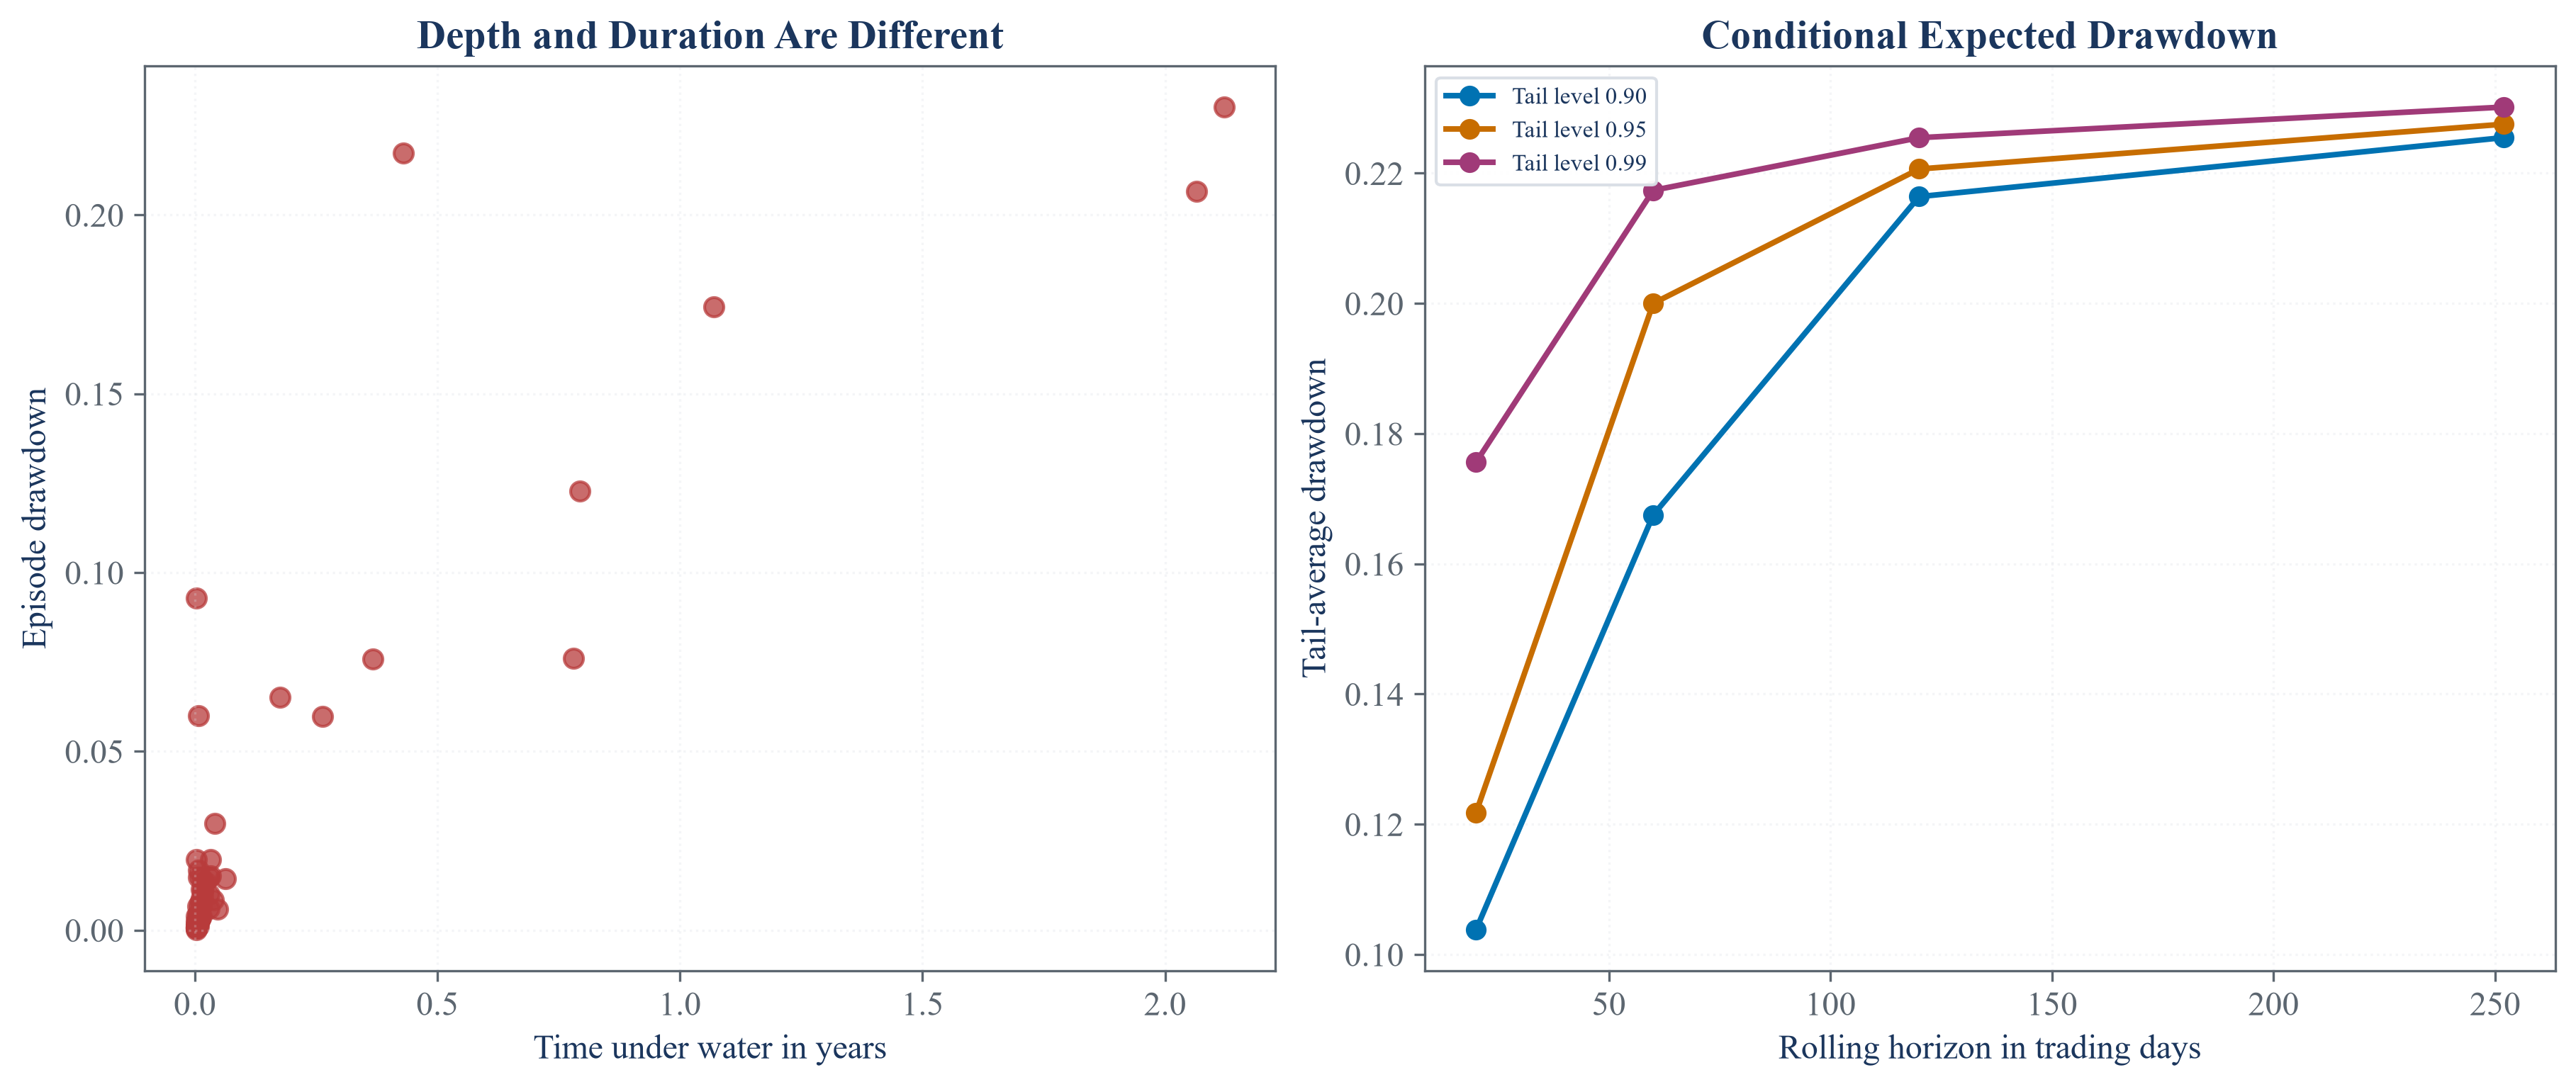

In [4]:
drawdown_episodes, time_under_water = compute_drawdowns_time_under_water(strategy_wealth, dollars=False)
drawdown_episode_table = pd.DataFrame({
    "Peak date": drawdown_episodes.index.strftime("%Y-%m-%d"),
    "Episode drawdown": drawdown_episodes.to_numpy(),
    "Time under water in years": time_under_water.reindex(drawdown_episodes.index).to_numpy(),
}).sort_values("Episode drawdown", ascending=False)
ced_rows = []
for horizon in [20, 60, 120, 252]:
    for alpha in [0.90, 0.95, 0.99]:
        ced_rows.append({"Horizon": horizon, "Tail level": alpha, "Conditional expected drawdown": conditional_expected_drawdown(strategy_returns.to_numpy(), horizon=horizon, alpha=alpha)})
ced_sensitivity = pd.DataFrame(ced_rows)
drawdown_summary = pd.DataFrame({
    "Quantity": ["Largest path drawdown", "Drawdown episodes", "Largest episode drawdown", "Longest time under water in years", "Sixty-day CED at 90 percent", "Sixty-day CED at 95 percent", "Sixty-day CED at 99 percent"],
    "Value": [drawdown_path.max(), len(drawdown_episodes), drawdown_episodes.max(), time_under_water.max(), conditional_expected_drawdown(strategy_returns.to_numpy(), 60, 0.90), conditional_expected_drawdown(strategy_returns.to_numpy(), 60, 0.95), conditional_expected_drawdown(strategy_returns.to_numpy(), 60, 0.99)],
})
save_table(drawdown_episode_table, "drawdown_episodes", "Public drawdown episodes and time under water.", "tab:chapter19-drawdown-episodes")
save_table(ced_sensitivity, "ced_sensitivity", "Conditional expected drawdown across horizons and tail levels.", "tab:chapter19-ced-sensitivity")
save_table(drawdown_summary, "drawdown_summary", "Drawdown summary for the public strategy.", "tab:chapter19-drawdown-summary", fit=False)
display(drawdown_episode_table)
display(ced_sensitivity)
display(drawdown_summary)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
axes[0].scatter(drawdown_episode_table["Time under water in years"], drawdown_episode_table["Episode drawdown"], color=palette["rose"], alpha=0.75, s=42)
axes[0].set_title("Depth and Duration Are Different")
axes[0].set_xlabel("Time under water in years")
axes[0].set_ylabel("Episode drawdown")
axes[0].grid(alpha=0.28)
for alpha, color in [(0.90, palette["cyan"]), (0.95, palette["amber"]), (0.99, palette["violet"])]:
    subset = ced_sensitivity[ced_sensitivity["Tail level"] == alpha]
    axes[1].plot(subset["Horizon"], subset["Conditional expected drawdown"], marker="o", color=color, linewidth=1.9, label=f"Tail level {alpha:.2f}")
axes[1].set_title("Conditional Expected Drawdown")
axes[1].set_xlabel("Rolling horizon in trading days")
axes[1].set_ylabel("Tail-average drawdown")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.28)
save_figure(figure, "drawdown_episode_ced_sensitivity")

## Repeated-History Stability

Repeated public-data block samples compare the relative sampling spread of two drawdown estimates:

$$
CV(\widehat R)=\frac{\operatorname{sd}(\widehat R_1,\ldots,\widehat R_M)}{\operatorname{mean}(\widehat R_1,\ldots,\widehat R_M)}.
$$

Here, $\widehat R_m$ is a drawdown estimate from repeated history $m$, $M$ is the number of repeated histories, $\operatorname{sd}$ is their sample standard deviation, $\operatorname{mean}$ is their average, and $CV$ is the coefficient of variation. Circular blocks retain short runs of the public returns while producing the repeated histories that one observed path cannot supply.

,Estimate,Repeated histories,History length,Block length,Mean,Standard deviation,Coefficient of variation,Fifth percentile,Ninety-fifth percentile
0,Maximum drawdown,300,500,20,0.194876,0.071495,0.366874,0.102050,0.335777
1,Conditional expected drawdown,300,500,20,0.154618,0.044139,0.285470,0.095578,0.242112


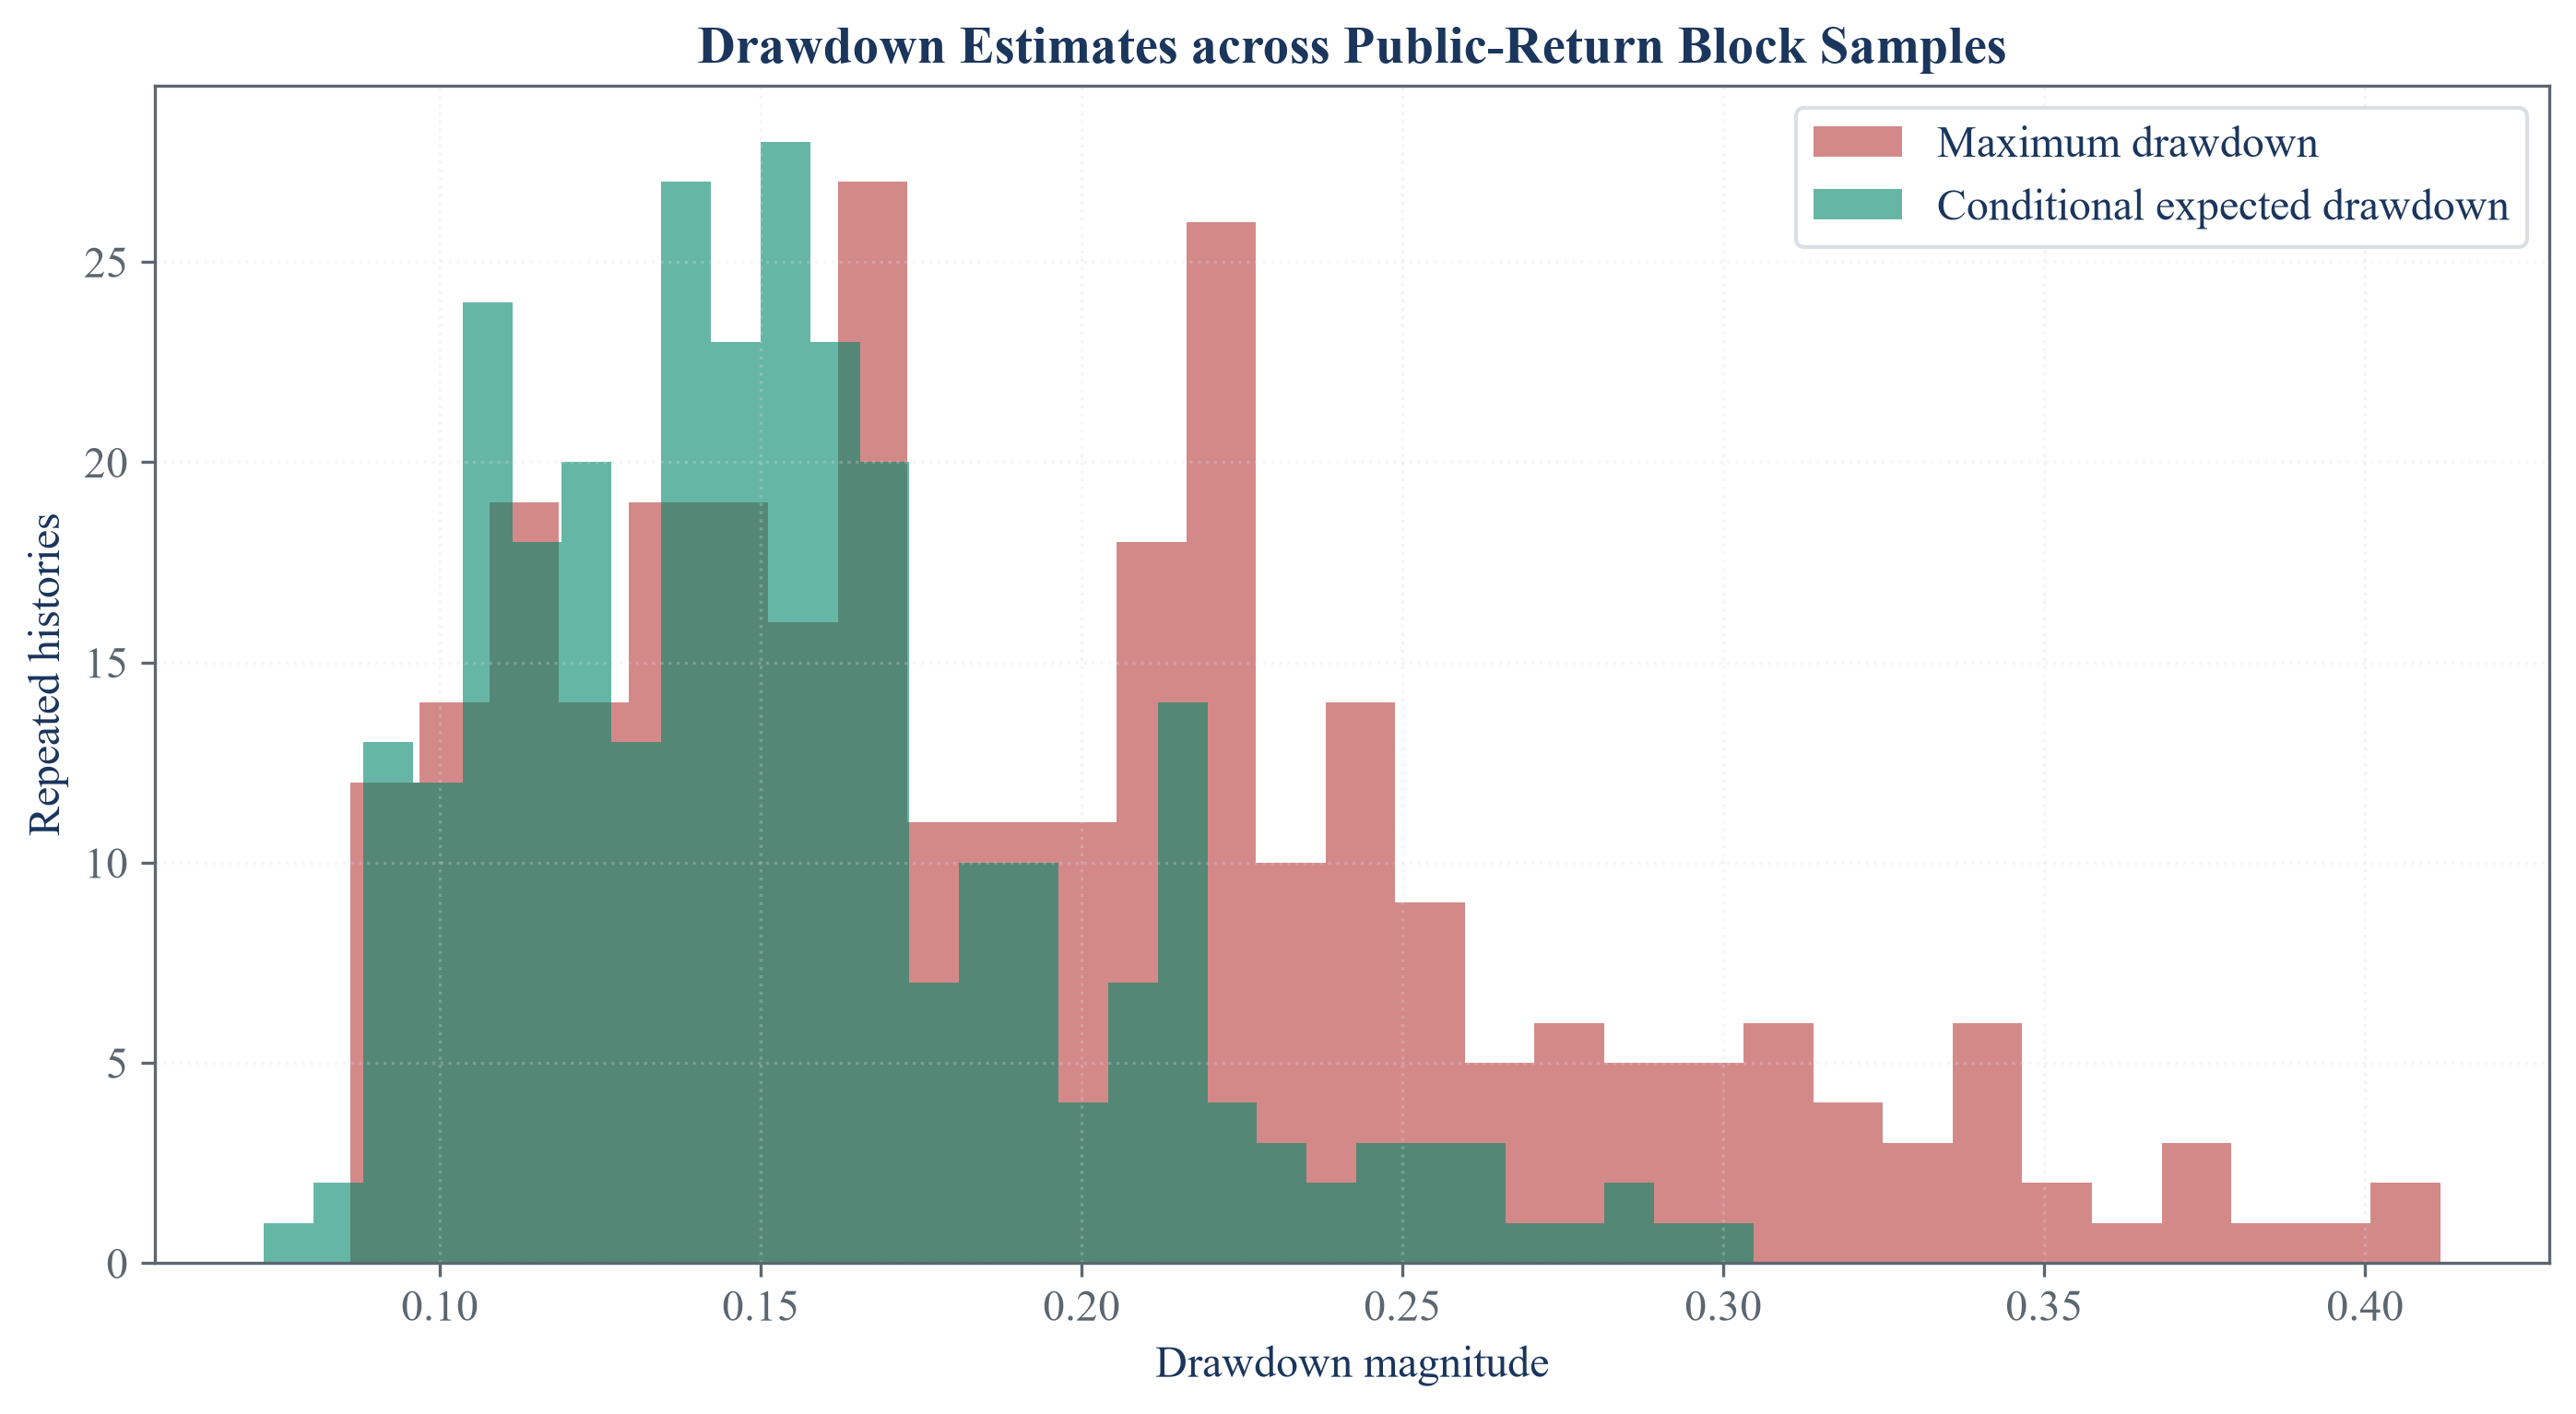

In [5]:
resample_rng = np.random.default_rng(20260928)
repeated_maximum_drawdowns = []
repeated_ced = []
repetitions = 300
sample_length = 500
block_length = 20
for repetition in range(repetitions):
    sample = circular_block_sample(strategy_returns.to_numpy(), sample_length, block_length, resample_rng)
    repeated_maximum_drawdowns.append(maximum_drawdown(sample))
    repeated_ced.append(conditional_expected_drawdown(sample, horizon=60, alpha=0.95))
repeated_maximum_drawdowns = np.asarray(repeated_maximum_drawdowns)
repeated_ced = np.asarray(repeated_ced)
resampled_drawdown_summary = pd.DataFrame({
    "Estimate": ["Maximum drawdown", "Conditional expected drawdown"],
    "Repeated histories": [repetitions, repetitions],
    "History length": [sample_length, sample_length],
    "Block length": [block_length, block_length],
    "Mean": [repeated_maximum_drawdowns.mean(), repeated_ced.mean()],
    "Standard deviation": [repeated_maximum_drawdowns.std(ddof=1), repeated_ced.std(ddof=1)],
    "Coefficient of variation": [repeated_maximum_drawdowns.std(ddof=1) / repeated_maximum_drawdowns.mean(), repeated_ced.std(ddof=1) / repeated_ced.mean()],
    "Fifth percentile": [np.quantile(repeated_maximum_drawdowns, 0.05), np.quantile(repeated_ced, 0.05)],
    "Ninety-fifth percentile": [np.quantile(repeated_maximum_drawdowns, 0.95), np.quantile(repeated_ced, 0.95)],
})
save_table(resampled_drawdown_summary, "resampled_drawdown_summary", "Sampling spread across circular block histories drawn from public returns.", "tab:chapter19-resampled-drawdown")
display(resampled_drawdown_summary)

figure, axis = plt.subplots(figsize=(9.2, 5.0), constrained_layout=True)
axis.hist(repeated_maximum_drawdowns, bins=30, alpha=0.60, color=palette["rose"], label="Maximum drawdown")
axis.hist(repeated_ced, bins=30, alpha=0.60, color=palette["green"], label="Conditional expected drawdown")
axis.set_title("Drawdown Estimates across Public-Return Block Samples")
axis.set_xlabel("Drawdown magnitude")
axis.set_ylabel("Repeated histories")
axis.legend()
axis.grid(alpha=0.28)
save_figure(figure, "resampled_drawdown_distributions")

## Linking trade precision to strategy risk

A two-outcome strategy has an annualized Sharpe ratio determined by its win chance, payoffs, and betting frequency:

$$
SR(p,n,\pi_-,\pi_+)=\frac{(\pi_+-\pi_-)p+\pi_-}{(\pi_+-\pi_-)\sqrt{p(1-p)}}\sqrt n.
$$

Here, $p$ is the probability of a profitable bet, $n$ is the number of bets per year, $\pi_+>0$ is the average profitable outcome, $\pi_-<0$ is the average losing outcome, and $SR$ is the annualized Sharpe ratio under independent two-outcome bets.

,Quantity,Value
0,Bets,84
1,Bets per year,9.183179
2,Profitable share,0.380952
3,Average profit,0.053001
4,Average loss,-0.020942
5,Two-outcome annual Sharpe,0.609871
6,Daily-return annual Sharpe,0.391955
7,Frequency needed for target Sharpe one,24.689769


,Target annual Sharpe,Required profitable share,Observed profitable share,Approximate probability below requirement
0,0,0.283220,0.380952,0.032554
1,0.5,0.362539,0.380952,0.364101
2,1,0.447297,0.380952,0.894737
3,1.5,0.530260,0.380952,0.997583
4,2,0.605747,0.380952,0.999989


,Bets per year,Target annual Sharpe,Required profitable share
0,5,0.5,0.392404
1,5,1,0.506806
2,5,1.5,0.610358
3,5,2,0.695015
4,10,0.5,0.359072
5,10,1,0.440199
6,10,1.5,0.520197
7,10,2,0.593830
8,25,0.5,0.330250
9,25,1,0.380313


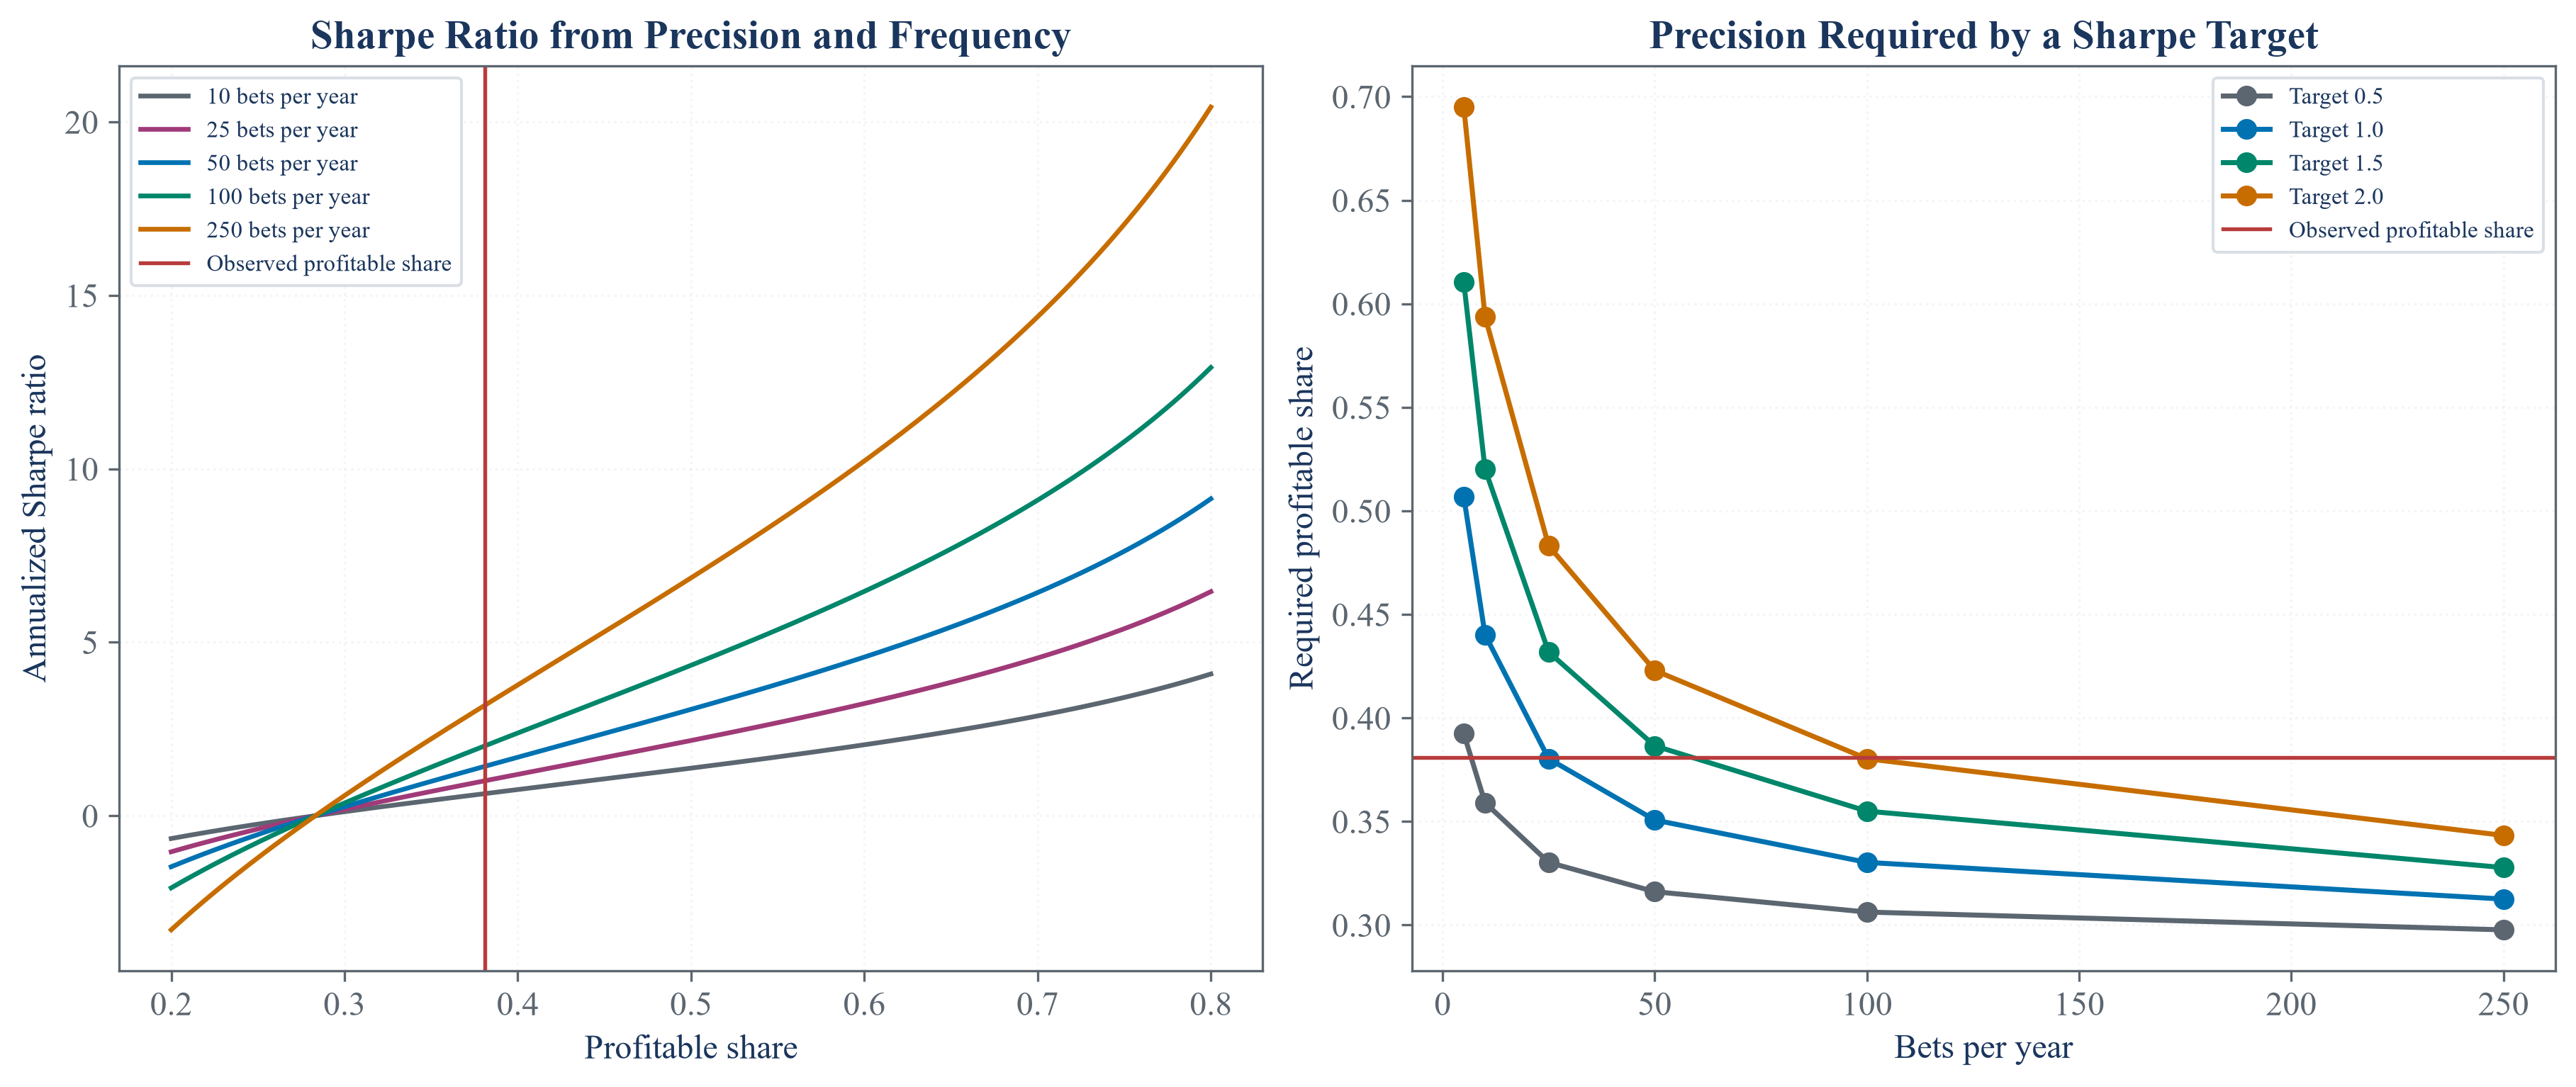

In [6]:
positive_bets = public_bets.loc[public_bets["Bet return"] > 0, "Bet return"]
negative_bets = public_bets.loc[public_bets["Bet return"] <= 0, "Bet return"]
observed_precision = len(positive_bets) / len(public_bets)
average_profit = positive_bets.mean()
average_loss = negative_bets.mean()
observed_frequency = len(public_bets) / elapsed_years
binary_sharpe = binomial_sharpe_ratio(average_loss, average_profit, observed_frequency, observed_precision)
risk_rows = []
for target_sharpe in [0.0, 0.5, 1.0, 1.5, 2.0]:
    required_precision = implied_precision(average_loss, average_profit, observed_frequency, target_sharpe)
    standard_error = np.sqrt(observed_precision * (1.0 - observed_precision) / len(public_bets))
    lower_tail_probability = ss.norm.cdf((required_precision - observed_precision) / standard_error)
    risk_rows.append({"Target annual Sharpe": target_sharpe, "Required profitable share": required_precision, "Observed profitable share": observed_precision, "Approximate probability below requirement": lower_tail_probability})
public_strategy_risk = pd.DataFrame(risk_rows)
strategy_risk_summary = pd.DataFrame({
    "Quantity": ["Bets", "Bets per year", "Profitable share", "Average profit", "Average loss", "Two-outcome annual Sharpe", "Daily-return annual Sharpe", "Frequency needed for target Sharpe one"],
    "Value": [len(public_bets), observed_frequency, observed_precision, average_profit, average_loss, binary_sharpe, sharpe_ratio(strategy_returns.to_numpy()) * np.sqrt(252.0), bin_frequency(average_loss, average_profit, observed_precision, 1.0)],
})
precision_rows = []
for frequency in [5, 10, 25, 50, 100, 250]:
    for target_sharpe in [0.5, 1.0, 1.5, 2.0]:
        precision_rows.append({"Bets per year": frequency, "Target annual Sharpe": target_sharpe, "Required profitable share": implied_precision(average_loss, average_profit, frequency, target_sharpe)})
precision_sensitivity = pd.DataFrame(precision_rows)
save_table(strategy_risk_summary, "strategy_risk_summary", "Two-outcome summary for the public strategy.", "tab:chapter19-strategy-risk-summary", fit=False)
save_table(public_strategy_risk, "public_strategy_risk", "Required precision and approximate lower-tail risk at several Sharpe targets.", "tab:chapter19-strategy-risk")
save_table(precision_sensitivity, "precision_sensitivity", "Required profitable shares as frequency and the Sharpe target change.", "tab:chapter19-precision-sensitivity")
display(strategy_risk_summary)
display(public_strategy_risk)
display(precision_sensitivity)

precision_axis = np.linspace(0.20, 0.80, 280)
figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
for frequency, color in [(10, palette["muted"]), (25, palette["violet"]), (50, palette["cyan"]), (100, palette["green"]), (250, palette["amber"])]:
    values = [binomial_sharpe_ratio(average_loss, average_profit, frequency, probability) for probability in precision_axis]
    axes[0].plot(precision_axis, values, color=color, linewidth=1.6, label=f"{frequency} bets per year")
axes[0].axvline(observed_precision, color=palette["rose"], linewidth=1.3, label="Observed profitable share")
axes[0].set_title("Sharpe Ratio from Precision and Frequency")
axes[0].set_xlabel("Profitable share")
axes[0].set_ylabel("Annualized Sharpe ratio")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.28)
for target_sharpe, color in [(0.5, palette["muted"]), (1.0, palette["cyan"]), (1.5, palette["green"]), (2.0, palette["amber"])]:
    subset = precision_sensitivity[precision_sensitivity["Target annual Sharpe"] == target_sharpe]
    axes[1].plot(subset["Bets per year"], subset["Required profitable share"], marker="o", color=color, linewidth=1.7, label=f"Target {target_sharpe:.1f}")
axes[1].axhline(observed_precision, color=palette["rose"], linewidth=1.3, label="Observed profitable share")
axes[1].set_title("Precision Required by a Sharpe Target")
axes[1].set_xlabel("Bets per year")
axes[1].set_ylabel("Required profitable share")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.28)
save_figure(figure, "strategy_risk_precision_frequency")

## Preliminary Checks with Known Inputs

A two-component normal mixture supplies known component means, spreads, and mixture weight for a direct calculation check:

$$
X\sim p\,\mathcal N(\mu_+,\sigma_+^2)+(1-p)\,\mathcal N(\mu_-,\sigma_-^2).
$$

Here, $X$ is a generated bet outcome, $p$ is the probability of drawing from the profitable component, $\mu_+$ and $\mu_-$ are the component means, and $\sigma_+$ and $\sigma_-$ are their standard deviations. The complete generation code is shown because the population component values must be known for this check.

In [7]:
np.random.seed(20260928)
mixture_half = mix_gaussians(10.0, -10.0, 1.0, 1.0, 0.5, 1000)
mixture_biased = mix_gaussians(10.0, -10.0, 1.0, 1.0, 0.8, 1000)
mixture_reproduction = pd.DataFrame({
    "Mixture weight": [0.5, 0.8],
    "Observations": [len(mixture_half), len(mixture_biased)],
    "Population mean": [0.0, 6.0],
    "Sample mean": [mixture_half.mean(), mixture_biased.mean()],
    "Sample standard deviation": [mixture_half.std(ddof=1), mixture_biased.std(ddof=1)],
})
preliminary_strategy_reproduction = pd.DataFrame({
    "Quantity": ["Target annual Sharpe", "Bets per year", "Profit amount", "Loss magnitude", "Observed profitable share", "Required share with a negative loss outcome", "Required share with a positive loss magnitude", "Sharpe at observed share"],
    "Value": [2.0, 52, 0.04, 0.02, 0.60, implied_precision(-0.02, 0.04, 52, 2.0), implied_precision(0.02, 0.04, 52, 2.0), binomial_sharpe_ratio(-0.02, 0.04, 52, 0.60)],
})
controlled_dates = pd.date_range("2020-01-01", periods=8)
controlled_positions = pd.Series([0, 1, 1, 0, -1, -1, 1, 0], index=controlled_dates)
controlled_bet_dates = bet_timing(controlled_positions)
controlled_holding_frame, controlled_holding_mean = calculate_holding_period(pd.Series([0, 1, 1, 0], index=pd.date_range("2020-01-01", periods=4)))
controlled_pnl = pd.Series([10, 9, 8, 10, 11, 10, 12, 11, 10, 12], index=pd.date_range("2020-01-01", periods=10))
controlled_drawdowns, controlled_time_under_water = compute_drawdowns_time_under_water(controlled_pnl, dollars=True)
controlled_backtest_checks = pd.DataFrame({
    "Quantity": ["Bet-ending dates", "Mean holding days", "Equal-return concentration", "Single-return concentration", "Drawdown episodes", "Largest dollar drawdown", "Longest controlled time under water in days"],
    "Value": [len(controlled_bet_dates), controlled_holding_mean, calculate_hhi(pd.Series([1, 1, 1, 1])), calculate_hhi(pd.Series([10, 0, 0, 0])), len(controlled_drawdowns), controlled_drawdowns.max(), controlled_time_under_water.max() * 365.25],
})
save_table(mixture_reproduction, "mixture_reproduction", "Known-input mixture checks retained from the released tests.", "tab:chapter19-mixture-reproduction")
save_table(preliminary_strategy_reproduction, "preliminary_strategy_reproduction", "Sign-sensitive reproduction of the preliminary strategy-risk example.", "tab:chapter19-preliminary-strategy", fit=False)
save_table(controlled_backtest_checks, "controlled_backtest_checks", "Controlled checks for bet timing, holding time, concentration, and drawdowns.", "tab:chapter19-controlled-backtest", fit=False)
display(mixture_reproduction)
display(preliminary_strategy_reproduction)
display(controlled_backtest_checks)

,Mixture weight,Observations,Population mean,Sample mean,Sample standard deviation
0,0.5,1000,0,0.007061,10.064420
1,0.8,1000,6,6.013815,8.054033


,Quantity,Value
0,Target annual Sharpe,2
1,Bets per year,52
2,Profit amount,0.040000
3,Loss magnitude,0.020000
4,Observed profitable share,0.600000
5,Required share with a negative loss outcome,0.471787
6,Required share with a positive loss magnitude,NaN
7,Sharpe at observed share,3.925227


,Quantity,Value
0,Bet-ending dates,3
1,Mean holding days,2
2,Equal-return concentration,0
3,Single-return concentration,1
4,Drawdown episodes,3
5,Largest dollar drawdown,2
6,Longest controlled time under water in days,3


## Tests

In [8]:
assert data_hash == EXPECTED_DATA_HASH
assert len(prices) == 2330
assert len(strategy_returns) == 2300
assert len(public_bets) == 84
assert np.isclose(elapsed_years, 9.14715947980835)
assert np.isclose(sharpe_ratio(strategy_returns.to_numpy()) * np.sqrt(252.0), 0.3919550723583464)
assert len(public_bet_dates) == 84
assert np.isclose(mean_holding_period, 39.855421686746986)
assert pd.Timestamp("2020-01-04") in controlled_bet_dates
assert pd.Timestamp("2020-01-07") in controlled_bet_dates
assert pd.Timestamp("2020-01-08") in controlled_bet_dates
assert np.isclose(controlled_holding_mean, 2.0)
assert np.isclose(calculate_hhi(pd.Series([1, 1, 1, 1])), 0.0)
assert np.isclose(calculate_hhi(pd.Series([10, 0, 0, 0])), 1.0)
assert len(controlled_drawdowns) == 3
assert np.isclose(controlled_drawdowns.iloc[0], 2.0)
assert np.isclose(controlled_time_under_water.iloc[0], 3.0 / 365.25)
assert 0 <= conditional_expected_drawdown(strategy_returns.to_numpy(), 60, 0.95) < 1
assert conditional_expected_drawdown(np.full(200, 0.001), 20, 0.95) == 0.0
assert resampled_drawdown_summary.shape == (2, 9)
assert resampled_drawdown_summary.loc[1, "Coefficient of variation"] < resampled_drawdown_summary.loc[0, "Coefficient of variation"]
assert np.isclose(binomial_sharpe_ratio(-0.01, 0.01, 252, 0.5), 0.0)
assert np.isclose(binomial_sharpe_ratio(-0.01, 0.01, 252, 0.6), 3.2403703492039306)
assert np.isclose(bin_frequency(-0.01, 0.01, 0.6, 3.2403703492039306), 252.0)
assert np.isclose(implied_precision(-0.01, 0.01, 252, 3.2396), 0.6, atol=1e-4)
assert len(mixture_half) == 1000
assert len(mixture_biased) == 1000
assert np.isclose(mixture_half.mean(), 0.0, atol=0.5)
assert np.isclose(mixture_biased.mean(), 6.0, atol=0.5)
assert str(target_sharpe_ratio_symbolic()) == "-p*(-d + u)**2*(p - 1)"
assert public_strategy_risk["Required profitable share"].is_monotonic_increasing
assert (FIGURES / "public_wealth_drawdown.pdf").exists()
assert (FIGURES / "public_positions_bet_timing.pdf").exists()
assert (FIGURES / "drawdown_episode_ced_sensitivity.pdf").exists()
assert (FIGURES / "resampled_drawdown_distributions.pdf").exists()
assert (FIGURES / "strategy_risk_precision_frequency.pdf").exists()
check_summary = pd.DataFrame({"Check": ["Public file identity", "Delayed public rule", "Bet timing", "Holding period", "Concentration bounds", "Drawdown episodes", "Conditional expected drawdown", "Repeated-history stability", "Two-outcome Sharpe", "Precision-frequency inverse", "Known mixture moments", "Symbolic variance"], "Status": ["Pass"] * 12})
display(check_summary)

,Check,Status
0,Public file identity,Pass
1,Delayed public rule,Pass
2,Bet timing,Pass
3,Holding period,Pass
4,Concentration bounds,Pass
5,Drawdown episodes,Pass
6,Conditional expected drawdown,Pass
7,Repeated-history stability,Pass
8,Two-outcome Sharpe,Pass
9,Precision-frequency inverse,Pass
